# 06 – Final Evaluation (test set)
All models evaluated once on the untouched test set: classification metrics, ranking quality, latency, error analysis and fairness check.

## Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd, numpy as np, os, time, joblib, torch
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ndcg_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from xgboost import XGBClassifier

base = "/content/drive/MyDrive/resume-jd-matching"
data_dir, model_dir = f"{base}/data", f"{base}/models"
rep_dir, fig_dir = f"{base}/reports", f"{base}/reports/figures"

train = pd.read_parquet(f"{data_dir}/train_feat.parquet")
test = pd.read_parquet(f"{data_dir}/test_feat.parquet")
order = ["No Fit", "Potential Fit", "Good Fit"]
y_te = test["label"]

FEATS = ["skill_coverage", "skill_jaccard", "matched_count", "missing_count", "jd_skill_count",
         "resume_skill_count", "jd_years", "resume_years", "exp_gap", "exp_meets",
         "jd_years_missing", "resume_years_missing", "tfidf_cosine", "embed_cosine"]

E = joblib.load(f"{data_dir}/embeddings.joblib")
emb = dict(zip(E["texts"], E["embeddings"]))
def pair_feats(df):
    J, R = np.stack(df["jd"].map(emb).values), np.stack(df["resume"].map(emb).values)
    return np.hstack([np.abs(J - R), J * R])
Xe_te = pair_feats(test)

def ordered_proba(m, X):
    P = m.predict_proba(X)
    return P[:, [list(m.classes_).index(c) for c in order]]

print(test.shape, "| JDs:", test["jd"].nunique(), "| GPU:", torch.cuda.is_available())

Mounted at /content/drive
(1759, 19) | JDs: 71 | GPU: False


## Predictions on test
Saved models are loaded. Keyword baseline and resume-only check were not saved in notebook 04, so they are retrained here with the same settings (deterministic).

In [ ]:
preds, probs, latency = {}, {}, {}

def run(name, model, X):
    t = time.time(); P = ordered_proba(model, X); latency[name] = (time.time() - t) / len(test) * 1000
    probs[name], preds[name] = P, np.array(order)[P.argmax(1)]

preds["Majority class"] = np.array(["No Fit"] * len(test))

kw = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
run("Keyword baseline", kw.fit(train[["tfidf_cosine"]], train["label"]), test[["tfidf_cosine"]])

ro = make_pipeline(TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True, max_features=20000),
                   LogisticRegression(class_weight="balanced", max_iter=2000))
run("Resume-only check", ro.fit(train["resume"], train["label"]), test["resume"])

run("Logistic Regression", joblib.load(f"{model_dir}/logreg.joblib"), test[FEATS])
run("Random Forest", joblib.load(f"{model_dir}/random_forest.joblib"), test[FEATS])
run("Sentence-BERT model", joblib.load(f"{model_dir}/sbert_logreg.joblib"), Xe_te)

meta = joblib.load(f"{model_dir}/xgb_hybrid_meta.joblib")
xgb = XGBClassifier(); xgb.load_model(f"{model_dir}/xgb_hybrid.json")
X_te_h = np.hstack([test[FEATS].values, meta["pca"].transform(Xe_te)])
t = time.time(); P = xgb.predict_proba(X_te_h); latency["XGBoost hybrid"] = (time.time() - t) / len(test) * 1000
probs["XGBoost hybrid"], preds["XGBoost hybrid"] = P, np.array(order)[P.argmax(1)]
print("Done:", list(preds))

Done: ['Majority class', 'Keyword baseline', 'Resume-only check', 'Logistic Regression', 'Random Forest', 'Sentence-BERT model', 'XGBoost hybrid']


## DistilBERT on test

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
dev = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(f"{model_dir}/distilbert")
dbm = AutoModelForSequenceClassification.from_pretrained(f"{model_dir}/distilbert").to(dev).eval()

out, t = [], time.time()
with torch.no_grad():
    for i in range(0, len(test), 32):
        b = test.iloc[i:i + 32]
        enc = tok(list(b["jd"]), list(b["resume"]), truncation="longest_first", max_length=512,
                  padding=True, return_tensors="pt").to(dev)
        out.append(dbm(**enc).logits.float().softmax(-1).cpu().numpy())
latency["DistilBERT"] = (time.time() - t) / len(test) * 1000
probs["DistilBERT"] = np.vstack(out)
preds["DistilBERT"] = np.array(order)[probs["DistilBERT"].argmax(1)]
print("DistilBERT done on", dev)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT done on cpu


## Test results: all models

In [ ]:
val_f1 = {"Majority class": 0.218, "Keyword baseline": 0.408, "Resume-only check": 0.426,
          "Logistic Regression": 0.463, "Random Forest": 0.498, "Sentence-BERT model": 0.527,
          "XGBoost hybrid": 0.545, "DistilBERT": 0.373}   # from the experiment log

res = pd.DataFrame([{"model": m, "val_macro_f1": val_f1[m],
                     "test_macro_f1": round(f1_score(y_te, p, average="macro"), 3),
                     "test_accuracy": round(accuracy_score(y_te, p), 3),
                     "ms_per_pair": round(latency.get(m, 0), 3)} for m, p in preds.items()])
res = res.sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
res.to_csv(f"{rep_dir}/test_results.csv", index=False)
print(res.to_string(index=False))

              model  val_macro_f1  test_macro_f1  test_accuracy  ms_per_pair
     XGBoost hybrid         0.545          0.500          0.548        0.167
      Random Forest         0.498          0.458          0.505        0.207
Sentence-BERT model         0.527          0.443          0.471        0.036
  Resume-only check         0.426          0.441          0.449        0.758
Logistic Regression         0.463          0.431          0.449        0.004
   Keyword baseline         0.408          0.368          0.423        0.004
         DistilBERT         0.373          0.352          0.381      942.249
     Majority class         0.218          0.218          0.487        0.000


## Final model: XGBoost hybrid

               precision    recall  f1-score   support

       No Fit      0.688     0.709     0.698       857
Potential Fit      0.378     0.435     0.405       444
     Good Fit      0.447     0.356     0.396       458

     accuracy                          0.548      1759
    macro avg      0.504     0.500     0.500      1759
 weighted avg      0.547     0.548     0.546      1759



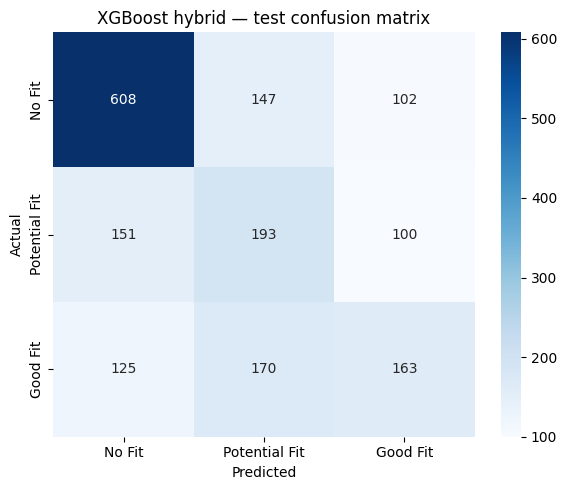

In [ ]:
final = "XGBoost hybrid"
print(classification_report(y_te, preds[final], labels=order, digits=3))

cm = confusion_matrix(y_te, preds[final], labels=order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("XGBoost hybrid — test confusion matrix")
plt.tight_layout(); plt.savefig(f"{fig_dir}/06_confusion_matrix.png", dpi=150); plt.show()

## Ranking quality
For each test JD with at least 2 different labels: rank its resumes by expected fit (P(Potential)×1 + P(Good)×2).
Precision@5 = share of the top 5 that are Potential or Good Fit. NDCG@5 uses graded relevance (No 0, Potential 1, Good 2).

In [ ]:
rel = y_te.map({"No Fit": 0, "Potential Fit": 1, "Good Fit": 2}).values

def rank_metrics(score, k=5):
    d = pd.DataFrame({"jd": test["jd"].values, "rel": rel, "score": score})
    p_at, nd = [], []
    for _, g in d.groupby("jd"):
        if g["rel"].nunique() < 2:
            continue
        kk = min(k, len(g))
        top = g.sort_values("score", ascending=False).head(kk)
        p_at.append((top["rel"] > 0).mean())
        nd.append(ndcg_score([g["rel"].values], [g["score"].values], k=kk))
    return round(np.mean(p_at), 3), round(np.mean(nd), 3), len(p_at)

rows = []
for m, P in probs.items():
    rows.append((m, *rank_metrics(P[:, 1] + 2 * P[:, 2])))
rows.append(("Keyword (raw TF-IDF cosine)", *rank_metrics(test["tfidf_cosine"].values)))
rng = np.random.default_rng(42)
rnd = np.array([rank_metrics(rng.random(len(test)))[:2] for _ in range(20)]).mean(0)
rows.append(("Random ranking (avg of 20)", round(rnd[0], 3), round(rnd[1], 3), rows[0][3]))

rank_df = pd.DataFrame(rows, columns=["model", "precision_at_5", "ndcg_at_5", "jds_used"]) \
            .sort_values("ndcg_at_5", ascending=False)
rank_df.to_csv(f"{rep_dir}/ranking_results.csv", index=False)
print(rank_df.to_string(index=False))

                      model  precision_at_5  ndcg_at_5  jds_used
              Random Forest           0.656      0.800        61
             XGBoost hybrid           0.662      0.781        61
        Sentence-BERT model           0.646      0.748        61
        Logistic Regression           0.580      0.738        61
          Resume-only check           0.613      0.656        61
                 DistilBERT           0.557      0.638        61
           Keyword baseline           0.528      0.634        61
Keyword (raw TF-IDF cosine)           0.528      0.634        61
 Random ranking (avg of 20)           0.486      0.536        61


## Error analysis

In [ ]:
err = test.assign(pred=preds[final])
err["correct"] = err["pred"] == err["label"]
print("Actual (rows) vs predicted (columns):\n", pd.crosstab(err["label"], err["pred"]).loc[order, order])
print("\nMedians — correct vs wrong, per actual label:")
print(err.groupby(["label", "correct"])[["skill_coverage", "embed_cosine", "tfidf_cosine", "exp_gap"]]
      .median().round(3).loc[order].to_string())

print("\n--- Examples: actual Good Fit, predicted No Fit ---")
for r in err[(err["label"] == "Good Fit") & (err["pred"] == "No Fit")].head(3).itertuples():
    print(f"\nskill_coverage={r.skill_coverage:.2f} | embed_cosine={r.embed_cosine:.2f} | exp_gap={r.exp_gap}")
    print("JD:", r.jd[:250], "...")
    print("Resume:", r.resume[:250], "...")
    print("Matched:", r.matched_skills or "-", "| Missing:", r.missing_skills or "-")

Actual (rows) vs predicted (columns):
 pred           No Fit  Potential Fit  Good Fit
label                                         
No Fit            608            147       102
Potential Fit     151            193       100
Good Fit          125            170       163

Medians — correct vs wrong, per actual label:
                       skill_coverage  embed_cosine  tfidf_cosine  exp_gap
label         correct                                                     
No Fit        False             0.333         0.499         0.046     -1.0
              True              0.176         0.413         0.026     -1.0
Potential Fit False             0.222         0.457         0.034      0.0
              True              0.333         0.492         0.038      1.0
Good Fit      False             0.273         0.458         0.037      0.0
              True              0.273         0.503         0.040      0.0

--- Examples: actual Good Fit, predicted No Fit ---

skill_coverage=0.11 | emb

## Fairness check
1. Features contain no protected attributes (name, gender, age, religion, caste, marital status, nationality).
2. Experience can act as a proxy for age, so performance is compared across experience bands.

In [ ]:
print("Features used:", FEATS, "+ 32 embedding PCA components (JD–resume comparisons only)")
bands = pd.cut(test["resume_years"], [-1, 5, 10, 60], labels=["0–5 yrs", "6–10 yrs", "10+ yrs"])
bands = bands.cat.add_categories("unknown").fillna("unknown")
fair = []
for b in ["0–5 yrs", "6–10 yrs", "10+ yrs", "unknown"]:
    mask = (bands == b).values
    if mask.sum() > 0:
        fair.append({"experience_band": b, "rows": int(mask.sum()),
                     "macro_f1": round(f1_score(y_te[mask], preds[final][mask], average="macro"), 3),
                     "pred_good_fit_rate": round((preds[final][mask] == "Good Fit").mean(), 3),
                     "actual_good_fit_rate": round((y_te[mask] == "Good Fit").mean(), 3)})
print(pd.DataFrame(fair).to_string(index=False))

Features used: ['skill_coverage', 'skill_jaccard', 'matched_count', 'missing_count', 'jd_skill_count', 'resume_skill_count', 'jd_years', 'resume_years', 'exp_gap', 'exp_meets', 'jd_years_missing', 'resume_years_missing', 'tfidf_cosine', 'embed_cosine'] + 32 embedding PCA components (JD–resume comparisons only)
experience_band  rows  macro_f1  pred_good_fit_rate  actual_good_fit_rate
        0–5 yrs   749     0.506               0.212                 0.271
       6–10 yrs   705     0.491               0.199                 0.278
        10+ yrs   254     0.506               0.205                 0.173
        unknown    51     0.328               0.275                 0.294


## Final evaluation findings (test set)
- XGBoost hybrid is best on test: macro F1 0.500, accuracy 0.548 (validation 0.545). All models dropped 0.02–0.08 from validation → validation (40 JDs, used for tuning) was slightly optimistic.
- Resume-only check reaches 0.441 on test; XGBoost beats it by 0.059 → labels partly depend on the resume itself (dataset limitation).
- Ranking (61 test JDs with ≥2 labels): XGBoost Precision@5 0.662, NDCG@5 0.781; Random Forest NDCG@5 0.800. Keyword 0.528 / 0.634, random 0.486 / 0.536, resume-only 0.613 / 0.656 → JD–resume comparison clearly improves shortlisting.
- Confusion: Good Fit recall 0.36 (170 → Potential Fit, 125 → No Fit). Errors are mostly between neighbouring classes.
- Errors include pairs that look mislabelled (e.g. a Sales Associate resume labelled Good Fit for a software role) → label noise limits achievable accuracy.
- Skill extraction weakness: "legal" picked up from JD boilerplate (work authorisation text).
- Latency (model step only): XGBoost 0.17 ms/pair vs DistilBERT 942 ms/pair on CPU.
- Fairness: no protected attributes used. Macro F1 even across experience bands (0.49–0.51). Mild skew: Good Fit slightly under-predicted for 0–10 yrs, slightly over for 10+ yrs. Unknown experience performs worse (0.328, 51 rows) → human review.
- Usability: suitable as decision support for shortlisting (about 2 in 3 top-5 candidates are real fits), not for automatic fit decisions (macro F1 0.50).

### Colab library versions
Compared with the laptop (sklearn 1.9.1, xgboost 3.4.1, numpy 2.5.3, sentence-transformers 6.1.0, pandas 3.0.6).

In [ ]:
import sklearn, xgboost, numpy, sentence_transformers, pandas
print("sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| numpy", numpy.__version__,
      "| sentence-transformers", sentence_transformers.__version__, "| pandas", pandas.__version__)

sklearn 1.6.1 | xgboost 3.4.1 | numpy 2.1.3 | sentence-transformers 5.7.0 | pandas 2.2.3


## Export version-independent artifacts for the app
Colab uses scikit-learn 1.6.1, the laptop 1.9.1. TF-IDF and PCA are saved as plain data (JSON / NumPy) so the app does not depend on scikit-learn pickles.

In [ ]:
import json, joblib, numpy as np
from google.colab import drive
drive.mount("/content/drive")
model_dir = "/content/drive/MyDrive/resume-jd-matching/models"

tf = joblib.load(f"{model_dir}/tfidf_vectorizer.joblib")
meta = joblib.load(f"{model_dir}/xgb_hybrid_meta.joblib")
pca = meta["pca"]

np.savez(f"{model_dir}/pca_32.npz", mean=pca.mean_, components=pca.components_)
with open(f"{model_dir}/tfidf.json", "w") as f:
    json.dump({"vocabulary": {k: int(v) for k, v in tf.vocabulary_.items()},
               "idf": tf.idf_.tolist(),
               "ngram_range": list(tf.ngram_range), "sublinear_tf": tf.sublinear_tf}, f)
with open(f"{model_dir}/xgb_hybrid_meta.json", "w") as f:
    json.dump({"features": meta["features"], "order": meta["order"], "feature_set": meta["feature_set"]}, f)

print("PCA:", pca.components_.shape, "| whiten:", pca.whiten,
      "| TF-IDF vocab:", len(tf.vocabulary_), "| features:", len(meta["features"]))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PCA: (32, 768) | whiten: False | TF-IDF vocab: 75675 | features: 14


## Export the validation JD list
The JD-grouped split can differ across scikit-learn versions, so the exact validation JDs are saved (as SHA-256 hashes of the cleaned JD text) for data_loader.py.

In [2]:
import hashlib, json, pandas as pd
from google.colab import drive
drive.mount("/content/drive")
data_dir = "/content/drive/MyDrive/resume-jd-matching/data"

val = pd.read_parquet(f"{data_dir}/val_clean.parquet")
tr = pd.read_parquet(f"{data_dir}/train_clean.parquet")
val_hashes = sorted({hashlib.sha256(t.encode("utf-8")).hexdigest() for t in val["jd"]})
with open(f"{data_dir}/val_jd_hashes.json", "w") as f:
    json.dump(val_hashes, f, indent=1)
print("Validation JDs:", len(val_hashes), "| val rows:", len(val), "| train rows:", len(tr))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Validation JDs: 40 | val rows: 943 | train rows: 5285
